## Загрузка

In [3]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
EXP_DIR = ROOT / "experiments"

rows = []
for path in sorted(EXP_DIR.glob("*/metrics_*.json")):
    data = json.loads(path.read_text(encoding="utf-8"))
    cfg = data["config"]["ingest"]
    rows.append({
        "tag": data["tag"],
        "embedding": cfg["embedding_model"].split("/")[-1],
        "chunk_size": cfg["chunk_size"],
        "overlap": cfg["chunk_overlap"],
        "hit@1": data["summary"]["hit_rate"]["@1"],
        "hit@3": data["summary"]["hit_rate"]["@3"],
        "hit@5": data["summary"]["hit_rate"]["@5"],
        "mrr": data["summary"]["mrr"],
        "timestamp": data["timestamp"],
    })

df = pd.DataFrame(rows).sort_values("mrr", ascending=False)
df

,tag,embedding,chunk_size,overlap,hit@1,hit@3,hit@5,mrr,timestamp
0,qdrant_minilm,all-MiniLM-L6-v2,512,64,0.13,0.225,0.305,0.188333,20261017_000037


## Bar chart по MRR

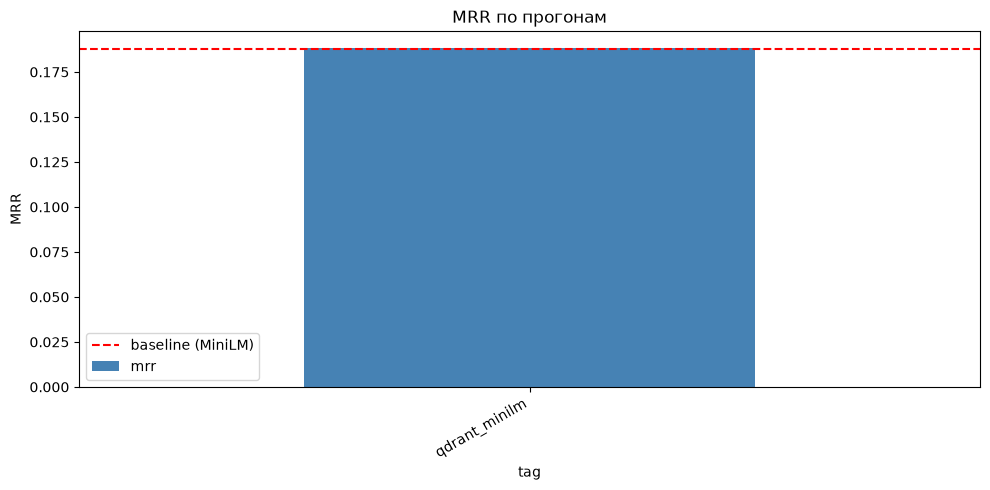

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
df.plot.bar(x="tag", y="mrr", ax=ax, legend=False, color="steelblue")
ax.set_ylabel("MRR")
ax.set_title("MRR по прогонам")
ax.axhline(0.188, color="red", linestyle="--", label="baseline (MiniLM)")
ax.legend()
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Сравнение метрик по группам

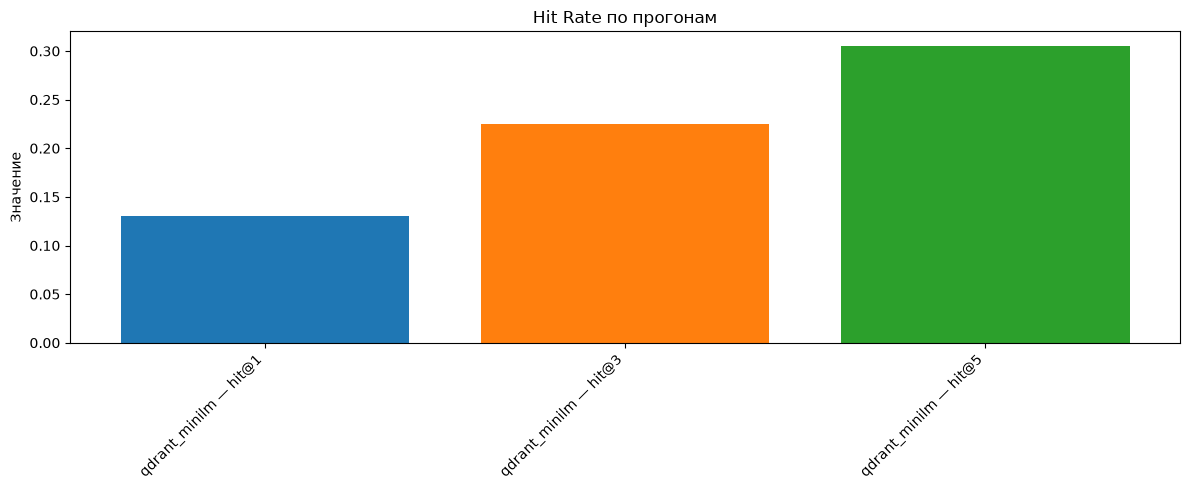

In [5]:
metrics = ["hit@1", "hit@3", "hit@5"]
df_melt = df.melt(id_vars="tag", value_vars=metrics, var_name="metric", value_name="value")

fig, ax = plt.subplots(figsize=(12, 5))
for metric, group in df_melt.groupby("metric"):
    ax.bar(group["tag"] + " — " + metric, group["value"], label=metric)

ax.set_ylabel("Значение")
ax.set_title("Hit Rate по прогонам")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()